### Executable Study E — layer contracts and isolated native construction

This authored demonstration uses a graph assembled by the Paper6 research assistant through actual native Langflow builder functions. Upper-plane packaging is proposed and coordinator-normalized. Cells below check and visualize source artifacts, not execute a ticket-triage workflow. Static consistency and readiness are different judgments.

In [1]:
from pathlib import Path
import json, sys, copy
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'knowledge/research/paper-6-study').exists())
study = ROOT / 'knowledge/research/paper-6-study'
sys.path.insert(0,str(study))
from layer_contract_engine import check, apply_revision, wire, construction_trace
instance = json.loads((study/'layers/instance-v1.json').read_text())
revised = json.loads((study/'layers/instance-v2.json').read_text())
native = json.loads((study/'assistant-workspace/artifacts/tower-native-v1-compact.json').read_text())
report = {name: check(doc,native) for name,doc in [('v1',instance),('v2',revised)]}
print(json.dumps(report,indent=2))
assert all(r['passed'] for r in report.values())
assert instance['requirements']==revised['requirements'] and instance['obligations']==revised['obligations']
assert instance['nativeGraphSha256']==revised['nativeGraphSha256'] and revised['parentRevision']==instance['revision']
print('Both authored revisions retain 10 open obligations; structural pass is NOT runtime readiness.')
trace = construction_trace(revised,native)
print('Controller stop:',trace['stop'])
display(Markdown('\n'.join(['| Step | Direction | Plane | Status |','|---|---|---|---|']+[f"| {r['step']} | {r['mode']} | {r['plane']} | {r['status']} |" for r in trace['trace']])))


{
  "v1": {
    "structuralAssertions": 139,
    "passed": true,
    "errors": [],
    "openObligations": 10,
    "readiness": "blocked by explicit obligations",
    "limits": "Authored structural contract, not learned hierarchy, useful behavior, scheduler implementation or human approval"
  },
  "v2": {
    "structuralAssertions": 139,
    "passed": true,
    "errors": [],
    "openObligations": 10,
    "readiness": "blocked by explicit obligations",
    "limits": "Authored structural contract, not learned hierarchy, useful behavior, scheduler implementation or human approval"
  }
}
Both authored revisions retain 10 open obligations; structural pass is NOT runtime readiness.
Controller stop: ask_for_missing_evidence


| Step | Direction | Plane | Status |
|---|---|---|---|
| 1 | decompose | processes | authored_proposal_inspected |
| 2 | decompose | flows | authored_proposal_inspected |
| 3 | decompose | composites | authored_proposal_inspected |
| 4 | decompose | components | authored_proposal_inspected |
| 5 | decompose | configuration | authored_proposal_inspected |
| 6 | ground | components | native_static_witness |
| 7 | check | composites | blocked |
| 8 | check | flows | blocked |
| 9 | check | processes | blocked |

In [2]:
rows=['| Plane | Units | Evidence tier | Unresolved gate |','|---|---:|---|---|']
for plane,items in instance['layers'].items():
    tier='Actual native static assembly' if plane=='components' else 'Authored proposal over native identities'
    gate={'configuration':'Approved prompt/model/resource binding','components':'Active ports and actual behavior','composites':'Purpose, boundary utility and behavior','flows':'Realized coordinator/termination/failure handling','processes':'Accountable human, policy and completion evidence'}[plane]
    rows.append(f"| {plane} | {len(items)} | {tier} | {gate} |")
display(Markdown('\n'.join(rows)))
rows=['| Open obligation | Target | Question |','|---|---|---|']
for o in instance['obligations']: rows.append(f"| {o['kind']} | {o['target']} | {o['question']} |")
display(Markdown('\n'.join(rows)))


| Plane | Units | Evidence tier | Unresolved gate |
|---|---:|---|---|
| configuration | 4 | Authored proposal over native identities | Approved prompt/model/resource binding |
| components | 4 | Actual native static assembly | Active ports and actual behavior |
| composites | 2 | Authored proposal over native identities | Purpose, boundary utility and behavior |
| flows | 1 | Authored proposal over native identities | Realized coordinator/termination/failure handling |
| processes | 1 | Authored proposal over native identities | Accountable human, policy and completion evidence |

| Open obligation | Target | Question |
|---|---|---|
| model_binding | Agent-bW6gg | Which approved model/resource should supply this Agent? No resource is bound. |
| prompt_approval | Agent-bW6gg | Approve or revise the proposed instructions before applying them. |
| model_binding | Agent-HUUnF | Which approved model/resource should supply this Agent? No resource is bound. |
| prompt_approval | Agent-HUUnF | Approve or revise the proposed instructions before applying them. |
| policy | process-triage | What is the approved triage policy and its version? |
| human_approval | process-triage | Who is accountable and what records explicit approval/rejection? |
| orchestration | flow-triage | Which coordinator enforces bounded completion, timeout, cancellation and failure handling? |
| source_context | Agent-HUUnF | How does review receive the original ticket, not only the generated draft? |
| behavior | process-triage | What independent tasks and acceptance evidence establish usefulness? |
| data_policy | process-triage | What confidentiality, redaction and retention rules apply? |

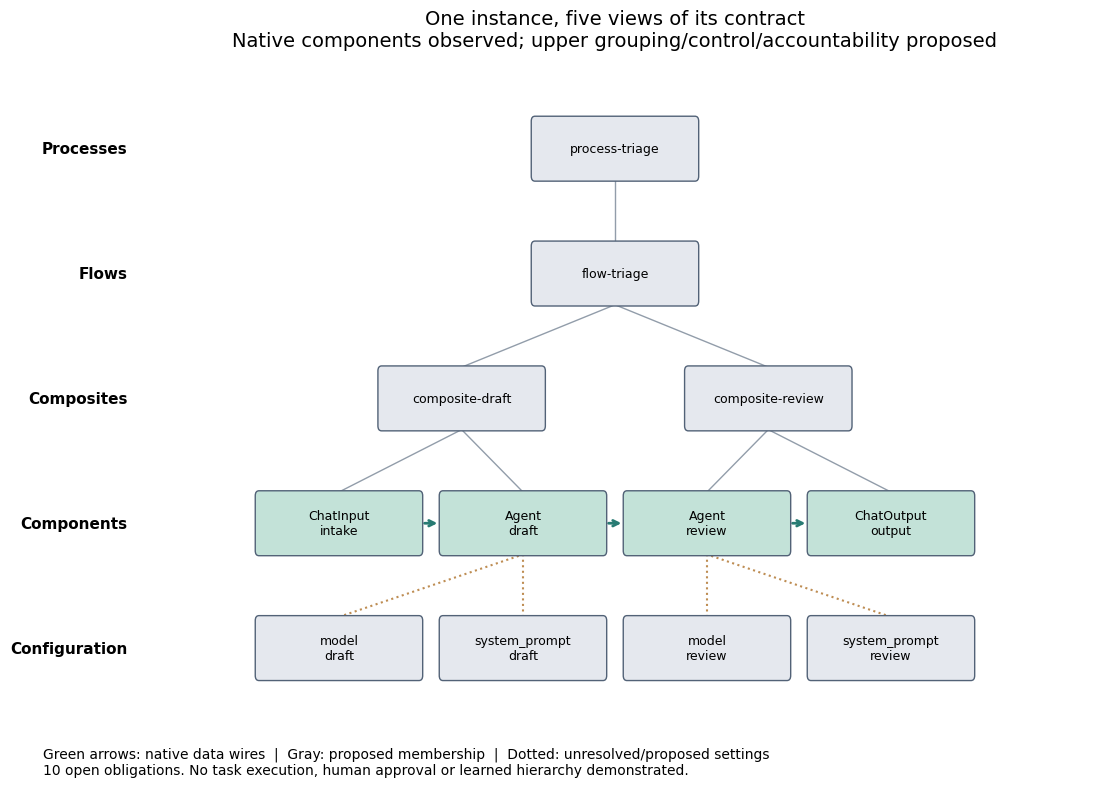

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
fig, ax=plt.subplots(figsize=(12,8))
levels=[('processes',4),('flows',3),('composites',2),('components',1),('configuration',0)]
labels={}
positions={}
for plane,y in levels:
    items=instance['layers'][plane]; xs=[(i+1)*10/(len(items)+1) for i in range(len(items))]
    for x,item in zip(xs,items):
        positions[item['id']]=(x,y)
        label=item.get('nativeType',item['id'])
        if plane=='components':label+='\n'+item['role']
        if plane=='configuration':label=item['field']+'\n'+('draft' if 'draft' in item['id'] else 'review')
        labels[item['id']]=label
        ax.add_patch(FancyBboxPatch((x-.87,y-.22),1.74,.44,boxstyle='round,pad=.04',facecolor='#c3e2d8' if plane=='components' else '#e5e8ee',edgecolor='#526277',zorder=3))
        ax.text(x,y,label,ha='center',va='center',fontsize=9,zorder=4)
    ax.text(-.3,y,plane.capitalize(),ha='right',va='center',fontweight='bold',fontsize=11)
for plane in ['composites','flows','processes']:
    for item in instance['layers'][plane]:
        for member in item['members']:
            x,y=positions[member];xx,yy=positions[item['id']]
            ax.plot([x,xx],[y+.25,yy-.25],color='#929daa',linewidth=1,zorder=1)
for cfg in instance['layers']['configuration']:
    x,y=positions[cfg['id']];xx,yy=positions[cfg['target']]
    ax.plot([x,xx],[y+.25,yy-.25],color='#be8d53',linestyle=':',linewidth=1.5,zorder=1)
for e in native['nativeFlow']['data']['edges']:
    x,y=positions[e['source']];xx,yy=positions[e['target']]
    ax.annotate('',(xx-.9,yy),(x+.9,y),arrowprops={'arrowstyle':'->','color':'#287b73','lw':2},zorder=2)
ax.set(xlim=(-.1,10.1),ylim=(-.6,4.6));ax.axis('off')
ax.set_title('One instance, five views of its contract\nNative components observed; upper grouping/control/accountability proposed',fontsize=14,pad=20)
fig.text(.12,.025,'Green arrows: native data wires  |  Gray: proposed membership  |  Dotted: unresolved/proposed settings\n10 open obligations. No task execution, human approval or learned hierarchy demonstrated.',fontsize=10)
fig.tight_layout(rect=(.08,.07,1,1));plt.show()


In [4]:
# Run actual fault-sensitivity tests; corrections and original findings remain recorded.
import unittest
from test_layer_contract_engine import LayerChecks
suite=unittest.defaultTestLoader.loadTestsFromTestCase(LayerChecks)
result=unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()
print('19 deliberately corrupted variants rejected by the finite checker; not an exhaustive validator claim.')
print('A prompt-only proposed revision preserves all requirements, obligations, native graph and occurrence identities.')
print('The reviewer still sees only the draft response, so original-ticket verification remains an explicit gap.')


test_baseline_structural_contract_with_open_obligations (test_layer_contract_engine.LayerChecks.test_baseline_structural_contract_with_open_obligations) ... 

ok


test_corruptions_detected (test_layer_contract_engine.LayerChecks.test_corruptions_detected) ... 

ok


test_finite_stage_gates (test_layer_contract_engine.LayerChecks.test_finite_stage_gates) ... 

ok


test_revision_scope (test_layer_contract_engine.LayerChecks.test_revision_scope) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.016s

OK


19 deliberately corrupted variants rejected by the finite checker; not an exhaustive validator claim.
A prompt-only proposed revision preserves all requirements, obligations, native graph and occurrence identities.
The reviewer still sees only the draft response, so original-ticket verification remains an explicit gap.
